# BUSI2066 Group K: Adidas Footwear Growth & Purchase Drivers
**Python analysis notebook** (supports the final report)

Business question: should adidas put its next footwear budget into **(a)** cross-selling shoes to apparel buyers or **(b)** design/comfort improvements, to lift footwear sales among 18-26 year olds?

**How to use**
1. Keep the Group K Qualtrics CSV in the same folder as this notebook (or update `RAW_PATH` below).
2. Run all cells top to bottom. The loader maps the text labels and rating values in this export; figures are saved to `figs/` and a cleaned, anonymised file to `adidas_clean_anonymised.csv`.
3. Copy the printed statistics into the report's Results tables.

Section A needs no raw data: it reproduces the figures that can be recovered from the Qualtrics dashboard summary.

In [42]:
import os, warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
os.makedirs("figs", exist_ok=True)
ALPHA = 0.05
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## A. Checks that use only the dashboard summary (no raw data needed)
Wilson 95% confidence intervals for proportions and one-sample t-tests of each importance factor against the scale midpoint (4 = neutral), computed from the published n, mean and SD.

In [43]:
def wilson(k, n, z=1.959964):
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return p, centre - half, centre + half

counts = {  # label: (k, n) taken from the Qualtrics dashboard export
    "Agreed to consent (of 82 answering)": (77, 82),
    "Aged 18-26 (of 76 answering age)": (62, 76),
    "Bought sneakers/athletic apparel, last 12m (of 56)": (50, 56),
    "Own adidas apparel (Q3, n=39)": (26, 39),
    "Own adidas footwear (Q4, n=39)": (29, 39),
    "Most recent pair: Nike (Q5, n=38)": (17, 38),
    "Most recent pair: adidas": (10, 38),
    "Most recent pair: Asics": (5, 38),
    "Most recent pair: Puma": (4, 38),
    "Most recent pair: Others": (2, 38),
    "Women (Q16, n=39)": (10, 39),
    "Men": (27, 39),
    "Non-binary": (2, 39),
    "5+ hours/day social media (Q17, n=39)": (18, 39),
}
rows = []
for lab, (k, n) in counts.items():
    p, lo, hi = wilson(k, n)
    rows.append([lab, k, n, f"{p:.1%}", f"[{lo:.1%}, {hi:.1%}]"])
print(pd.DataFrame(rows, columns=["Measure", "k", "n", "Share", "95% Wilson CI"]).to_string(index=False))

# Nike vs adidas among the 27 respondents whose latest pair was one of the two
print("\nNike vs adidas (17 vs 10), exact binomial test, H0: 50/50 -> p =",
      round(stats.binomtest(17, 27, 0.5).pvalue, 3))
print("Chi-square goodness of fit, equal brand shares (17,10,4,5,2):",
      stats.chisquare([17, 10, 4, 5, 2]))

                                           Measure  k  n Share  95% Wilson CI
               Agreed to consent (of 82 answering) 77 82 93.9% [86.5%, 97.4%]
                  Aged 18-26 (of 76 answering age) 62 76 81.6% [71.4%, 88.7%]
Bought sneakers/athletic apparel, last 12m (of 56) 50 56 89.3% [78.5%, 95.0%]
                     Own adidas apparel (Q3, n=39) 26 39 66.7% [51.0%, 79.4%]
                    Own adidas footwear (Q4, n=39) 29 39 74.4% [58.9%, 85.4%]
                 Most recent pair: Nike (Q5, n=38) 17 38 44.7% [30.1%, 60.3%]
                          Most recent pair: adidas 10 38 26.3% [15.0%, 42.0%]
                           Most recent pair: Asics  5 38 13.2%  [5.8%, 27.3%]
                            Most recent pair: Puma  4 38 10.5%  [4.2%, 24.1%]
                          Most recent pair: Others  2 38  5.3%  [1.5%, 17.3%]
                                 Women (Q16, n=39) 10 39 25.6% [14.6%, 41.1%]
                                               Men 27 39 69.2% [

In [44]:
# Importance factors: n, mean, SD from the dashboard (sneakers = Q6-Q10, apparel = Q11)
summ = {
    "Sneakers": {"Price": (39, 5.03, 1.12), "Style & design": (39, 5.77, 1.05), "Comfort & fit": (39, 5.56, 1.15),
                 "Brand image": (38, 4.63, 1.33), "Influencer approval": (39, 4.18, 1.84)},
    "Apparel":  {"Price": (37, 5.38, 1.32), "Style & design": (37, 5.57, 1.15), "Comfort & fit": (37, 5.46, 1.29),
                 "Brand image": (37, 4.54, 1.37), "Influencer approval": (37, 4.00, 1.86)},
}
out = []
for cat, d in summ.items():
    for f, (n, m, s) in d.items():
        se = s / np.sqrt(n)
        t = (m - 4) / se
        p = 2 * stats.t.sf(abs(t), n - 1)
        lo, hi = stats.t.interval(0.95, n - 1, m, se)
        out.append([cat, f, n, m, s, f"[{lo:.2f}, {hi:.2f}]", round(t, 2), round(p, 4)])
tt = pd.DataFrame(out, columns=["Category", "Factor", "n", "Mean", "SD", "95% CI", "t vs 4", "p"])
print(tt.to_string(index=False))

Category              Factor  n  Mean   SD       95% CI  t vs 4      p
Sneakers               Price 39  5.03 1.12 [4.67, 5.39]    5.74 0.0000
Sneakers      Style & design 39  5.77 1.05 [5.43, 6.11]   10.53 0.0000
Sneakers       Comfort & fit 39  5.56 1.15 [5.19, 5.93]    8.47 0.0000
Sneakers         Brand image 38  4.63 1.33 [4.19, 5.07]    2.92 0.0059
Sneakers Influencer approval 39  4.18 1.84 [3.58, 4.78]    0.61 0.5449
 Apparel               Price 37  5.38 1.32 [4.94, 5.82]    6.36 0.0000
 Apparel      Style & design 37  5.57 1.15 [5.19, 5.95]    8.30 0.0000
 Apparel       Comfort & fit 37  5.46 1.29 [5.03, 5.89]    6.88 0.0000
 Apparel         Brand image 37  4.54 1.37 [4.08, 5.00]    2.40 0.0218
 Apparel Influencer approval 37  4.00 1.86 [3.38, 4.62]    0.00 1.0000


## B. Load, clean and anonymise the raw Qualtrics export

In [45]:
RAW_PATH = "Group K - Adidas_November 11, 2026_14.43.csv"
CLEAN_PATH = "adidas_clean_anonymised.csv"

# Column names in the Group K Qualtrics export.
COL = {
    "consent": "Survey Statement",
    "age": "Q1",
    "bought": "Q2",
    "own_app": "Q3",
    "own_shoe": "Q4",
    "brand": "Q5",
    "sneaker": ["Q6-Q10_1", "Q6-Q10_2", "Q6-Q10_3", "Q6-Q10_4", "Q6-Q10_5"],
    "apparel": ["Q11_1", "Q11_2", "Q11_3", "Q11_4", "Q11_5"],  # same five factors for apparel
    "attitude": ["Q12-14_1", "Q12-14_2", "Q12-14_3"],
    "intent": "Q15_1",
    "gender": "Q16",
    "social": "Q17",
}
FACTORS = ["Price", "Style & design", "Comfort & fit", "Brand image", "Influencer approval"]
BRAND_CODES = {1: "Nike", 2: "Adidas", 4: "Puma", 5: "Asics", 6: "Others"}   # code 3 had no responses: check the survey
GENDER_CODES = {1: "Woman", 2: "Man", 3: "Non-binary", 4: "Prefer not to say"}
SOCIAL_CODES = {1: "Under 1h", 2: "1-2h", 3: "3-4h", 4: "5h or more"}

raw = pd.read_csv(RAW_PATH, encoding="utf-8-sig", skiprows=[1, 2])
if "Progress" in raw.columns:
    raw = raw[pd.to_numeric(raw["Progress"], errors="coerce").notna()].copy()
if "Status" in raw.columns:   # drop survey previews / test responses
    raw = raw[~raw["Status"].astype(str).str.contains("Preview|Spam", case=False, na=False)].copy()

needed = [COL[k] for k in ["consent","age","bought","own_app","own_shoe","brand","intent","gender","social"]]
needed += COL["sneaker"] + COL["apparel"] + COL["attitude"]
missing = [c for c in needed if c not in raw.columns]
assert not missing, f"These columns are not in your export, edit COL: {missing}\nAvailable: {list(raw.columns)}"

# The export stores category labels as text and some Likert endpoints with labels.
category_maps = {
    COL["consent"]: {"I agree.": 1, "I do not agree.": 2},
    COL["age"]: {"Under 18": 1, "18-26": 2, "27 or older": 3},
    COL["bought"]: {"Yes": 1, "No": 2},
    COL["own_app"]: {"Yes": 1, "No": 2},
    COL["own_shoe"]: {"Yes": 1, "No": 2},
    COL["brand"]: {"Nike": 1, "Adidas": 2, "Puma": 4, "Asics": 5, "Others": 6},
    COL["gender"]: {"Woman": 1, "Man": 2, "Non-binary": 3, "Prefer not to say": 4},
    COL["social"]: {"Under 1h": 1, "1-2": 2, "3-4": 3, "5 or more": 4},
}
for c, mapping in category_maps.items():
    values = raw[c].astype("string").str.strip().replace("", pd.NA)
    unknown = sorted(set(values.dropna().unique()) - set(mapping))
    if unknown:
        raise ValueError(f"Unexpected responses in {c}: {unknown}")
    raw[c] = values.map(mapping)

rating_cols = COL["sneaker"] + COL["apparel"] + COL["attitude"] + [COL["intent"]]
for c in rating_cols:
    values = raw[c].astype("string").str.strip().replace("", pd.NA)
    numeric = values.str.extract(r"^\s*(\d+(?:\.\d+)?)", expand=False)
    invalid = values.notna() & numeric.isna()
    if invalid.any():
        raise ValueError(f"Unexpected rating values in {c}: {sorted(values[invalid].unique())}")
    raw[c] = pd.to_numeric(numeric, errors="coerce")
for c in needed:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
print("Responses recorded:", len(raw))

Responses recorded: 83


In [46]:
# --- Respondent funnel (explains the sample size used in the report) ---
f = raw
funnel = [("Responses recorded", len(f))]
funnel.append(("Answered consent", int(f[COL["consent"]].notna().sum())))
f = f[f[COL["consent"]] == 1];            funnel.append(("Agreed to consent", len(f)))
funnel.append(("Answered age", int(f[COL["age"]].notna().sum())))
f = f[f[COL["age"]] == 2];                funnel.append(("Aged 18-26", len(f)))
funnel.append(("Answered purchase screener", int(f[COL["bought"]].notna().sum())))
f = f[f[COL["bought"]] == 1];             funnel.append(("Bought in last 12 months", len(f)))
core = [COL["own_app"], COL["own_shoe"], COL["intent"], COL["gender"], COL["social"]]
df = f[f[core].notna().all(axis=1)].copy()
funnel.append(("Completed Q3-Q17 (analysis sample)", len(df)))
funnel = pd.DataFrame(funnel, columns=["Stage", "n"])
print(funnel.to_string(index=False))

# --- Recoding ---
yes = lambda s: s.map({1: "Yes", 2: "No"})
df["own_apparel"] = yes(df[COL["own_app"]])
df["own_footwear"] = yes(df[COL["own_shoe"]])
df["last_brand"] = df[COL["brand"]].map(BRAND_CODES)
df["gender"] = df[COL["gender"]].map(GENDER_CODES)
df["social_hours"] = df[COL["social"]].map(SOCIAL_CODES)

# Q15: 'Cannot judge' (0) is NOT a score on the 1-7 scale -> treat as missing (as in the analysis plan)
df["intent_raw"] = df[COL["intent"]]
df["intent"] = df[COL["intent"]].where(df[COL["intent"]].between(1, 7))
print("\nQ15 'Cannot judge' responses recoded to missing:", int((df["intent_raw"] == 0).sum()))

for i, name in enumerate(FACTORS):
    df["sneaker_" + name] = df[COL["sneaker"][i]]
    df["apparel_" + name] = df[COL["apparel"][i]]

# Attitude index = mean of the three 0-100 sliders (needs at least 2 valid answers)
att = df[COL["attitude"]]
df["attitude_index"] = att.mean(axis=1).where(att.notna().sum(axis=1) >= 2)

def cronbach_alpha(x):
    x = x.dropna()
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))
print("Cronbach alpha, attitude items:", round(cronbach_alpha(att), 3))

# Mutually exclusive ownership groups for RQ4
def group3(r):
    if r["own_footwear"] == "Yes": return "Footwear owner"
    if r["own_apparel"] == "Yes":  return "Apparel only"
    return "Neither"
def group4(r):
    return {("Yes","Yes"):"Apparel + footwear", ("Yes","No"):"Apparel only",
            ("No","Yes"):"Footwear only", ("No","No"):"Neither"}[(r["own_apparel"], r["own_footwear"])]
df["group3"] = df.apply(group3, axis=1)
df["group4"] = df.apply(group4, axis=1)

                             Stage  n
                Responses recorded 83
                  Answered consent 80
                 Agreed to consent 75
                      Answered age 69
                        Aged 18-26 59
        Answered purchase screener 54
          Bought in last 12 months 48
Completed Q3-Q17 (analysis sample) 37

Q15 'Cannot judge' responses recoded to missing: 4
Cronbach alpha, attitude items: 0.874


In [47]:
# --- Anonymised, cleaned file for submission (no IP, location, dates, names, e-mail, ResponseId) ---
keep = ["own_apparel", "own_footwear", "last_brand", "intent_raw", "intent", "attitude_index",
        "gender", "social_hours", "group3", "group4"]
keep += ["sneaker_" + n for n in FACTORS] + ["apparel_" + n for n in FACTORS] + COL["attitude"]
clean = df[keep].reset_index(drop=True)
clean.insert(0, "respondent_id", np.arange(1, len(clean) + 1))
clean.to_csv(CLEAN_PATH, index=False)
print("Saved", CLEAN_PATH, clean.shape)
print("\nMissing values per column:"); print(clean.isna().sum()[clean.isna().sum() > 0])

Saved adidas_clean_anonymised.csv (37, 24)

Missing values per column:
last_brand                     1
intent                         4
attitude_index                 2
sneaker_Brand image            1
apparel_Price                  1
apparel_Style & design         1
apparel_Comfort & fit          1
apparel_Brand image            1
apparel_Influencer approval    1
Q12-14_1                       1
Q12-14_2                       2
Q12-14_3                       2
dtype: int64


## C. Descriptive statistics


own_apparel
               n     %
own_apparel          
Yes          24  64.9
No           13  35.1

own_footwear
                n     %
own_footwear          
Yes           27  73.0
No            10  27.0

last_brand
              n     %
last_brand          
Nike        16  43.2
Adidas       9  24.3
Asics        5  13.5
Puma         4  10.8
Others       2   5.4
NaN          1   2.7

gender
              n     %
gender              
Man         27  73.0
Woman        9  24.3
Non-binary   1   2.7

social_hours
                n     %
social_hours          
3-4h          17  45.9
5h or more    16  43.2
1-2h           4  10.8

group3
                  n     %
group3                  
Footwear owner  27  73.0
Neither          6  16.2
Apparel only     4  10.8

group4
                      n     %
group4                      
Apparel + footwear  20  54.1
Footwear only        7  18.9
Neither              6  16.2
Apparel only         4  10.8

                              count   mean    st

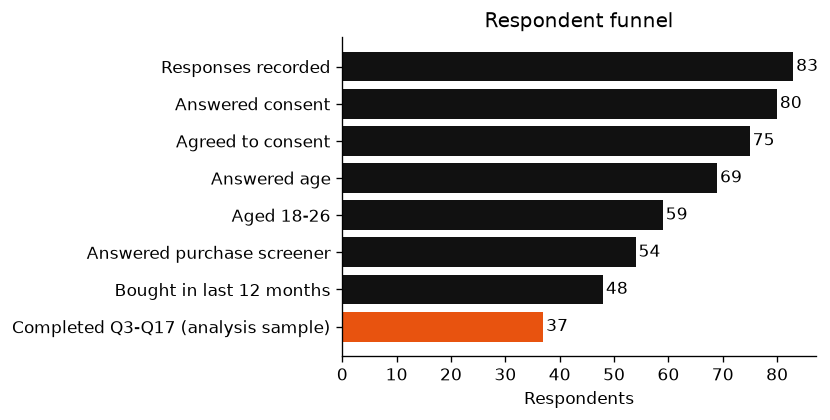

In [48]:
for c in ["own_apparel", "own_footwear", "last_brand", "gender", "social_hours", "group3", "group4"]:
    t = clean[c].value_counts(dropna=False).rename("n").to_frame()
    t["%"] = (t["n"] / t["n"].sum() * 100).round(1)
    print(f"\n{c}\n", t)

num = ["intent"] + COL["attitude"] + ["attitude_index"] + ["sneaker_" + n for n in FACTORS] + ["apparel_" + n for n in FACTORS]
print("\n", clean[num].describe().T[["count", "mean", "std", "min", "max"]].round(2))

# Figure 1: respondent funnel
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(funnel["Stage"][::-1], funnel["n"][::-1], color="#111")
ax.barh(funnel["Stage"].iloc[-1], funnel["n"].iloc[-1], color="#e8530f")
for y, v in enumerate(funnel["n"][::-1]): ax.text(v + 0.5, y, str(v), va="center")
ax.set_xlabel("Respondents"); ax.set_title("Respondent funnel")
plt.tight_layout(); plt.savefig("figs/fig1_funnel.png"); plt.show()

## D. RQ1: Ownership overlap and rival brands
**H0**: owning adidas footwear is independent of owning adidas apparel. **H1**: they are associated.
Tests: cross-tab, chi-square (Fisher's exact test when expected counts < 5), Wilson CI for the share of apparel owners who also own footwear, and the brand split of the latest sneaker purchase.

own_footwear  No  Yes  All
own_apparel               
No             6    7   13
Yes            4   20   24
All           10   27   37 

Expected counts:
 own_footwear    No    Yes
own_apparel              
No            3.51   9.49
Yes           6.49  17.51
Chi-square(1) = 3.718, p = 0.0538, Cramer's V = 0.317
Fisher exact: odds ratio = 4.29, p = 0.1178   (use this if any expected count < 5)

Apparel owners who also own adidas footwear: 20/24 = 83.3%, 95% CI [64.1%, 93.3%]

Most recent sneaker brand (all analysis sample):
              n     %
last_brand          
Nike        16  44.4
Adidas       9  25.0
Asics        5  13.9
Puma         4  11.1
Others       2   5.6
Nike vs adidas exact binomial p = 0.23

Latest brand by apparel ownership (row %):
 last_brand   Adidas  Asics  Nike  Others  Puma
own_apparel                                   
No             25.0   16.7  33.3    16.7   8.3
Yes            25.0   12.5  50.0     0.0  12.5


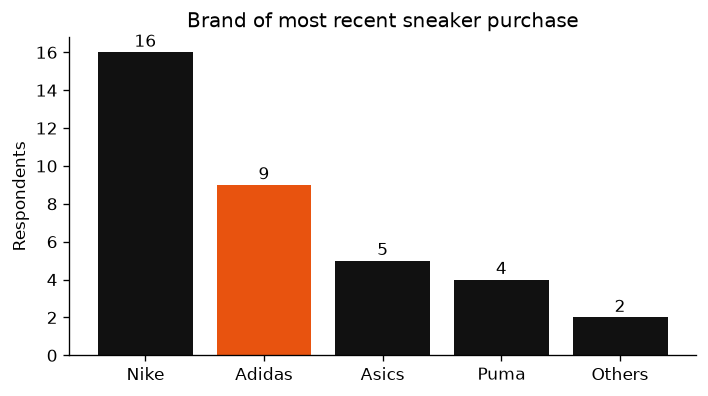

In [49]:
ct = pd.crosstab(clean["own_apparel"], clean["own_footwear"], margins=True)
print(ct, "\n")
ct2 = pd.crosstab(clean["own_apparel"], clean["own_footwear"])
chi2, p, dof, exp = stats.chi2_contingency(ct2, correction=False)
print("Expected counts:\n", pd.DataFrame(exp, index=ct2.index, columns=ct2.columns).round(2))
print(f"Chi-square({dof}) = {chi2:.3f}, p = {p:.4f}, Cramer's V = {np.sqrt(chi2 / ct2.values.sum()):.3f}")
if ct2.shape == (2, 2):
    odds, p_f = stats.fisher_exact(ct2.loc[["Yes", "No"], ["Yes", "No"]])
    print(f"Fisher exact: odds ratio = {odds:.2f}, p = {p_f:.4f}   (use this if any expected count < 5)")

app = clean[clean["own_apparel"] == "Yes"]
k, n = int((app["own_footwear"] == "Yes").sum()), len(app)
pp, lo, hi = wilson(k, n)
print(f"\nApparel owners who also own adidas footwear: {k}/{n} = {pp:.1%}, 95% CI [{lo:.1%}, {hi:.1%}]")

b = clean["last_brand"].value_counts()
bt = pd.DataFrame({"n": b, "%": (b / b.sum() * 100).round(1)})
print("\nMost recent sneaker brand (all analysis sample):\n", bt)
if {"Nike", "Adidas"} <= set(b.index):
    kn, ka = int(b["Nike"]), int(b["Adidas"])
    print("Nike vs adidas exact binomial p =", round(stats.binomtest(kn, kn + ka, 0.5).pvalue, 3))
ba = pd.crosstab(clean["own_apparel"], clean["last_brand"], normalize="index").round(3) * 100
print("\nLatest brand by apparel ownership (row %):\n", ba)

fig, ax = plt.subplots(figsize=(6, 3.4))
order = b.index
ax.bar(order, b.values, color=["#111" if x != "Adidas" else "#e8530f" for x in order])
for i, v in enumerate(b.values): ax.text(i, v + 0.3, str(v), ha="center")
ax.set_ylabel("Respondents"); ax.set_title("Brand of most recent sneaker purchase")
plt.tight_layout(); plt.savefig("figs/fig2_brand.png"); plt.show()

## E. RQ2: Sneaker vs apparel choice factors
**H0**: mean importance of each factor is the same for sneakers and apparel. **H1**: it differs.
Paired-samples t-test per factor (same respondent rates both), Holm correction for 5 tests, Wilcoxon signed-rank as a robustness check, Cohen's dz as effect size.

             Factor  n  Sneaker mean  Apparel mean  Diff (S-A)   95% CI diff      t     p  Wilcoxon p  Cohen dz  p (Holm)  Rank sneakers  Rank apparel
              Price 36         5.056         5.333      -0.278 [-0.57, 0.01] -1.963 0.058       0.058    -0.327     0.288              3             3
     Style & design 36         5.778         5.528       0.250 [-0.06, 0.56]  1.655 0.107       0.084     0.276     0.427              1             1
      Comfort & fit 36         5.639         5.417       0.222 [-0.10, 0.55]  1.390 0.173       0.133     0.232     0.520              2             2
        Brand image 35         4.629         4.457       0.171 [-0.13, 0.48]  1.139 0.263       0.233     0.192     0.520              4             4
Influencer approval 36         4.194         3.917       0.278 [-0.20, 0.76]  1.168 0.251       0.293     0.195     0.520              5             5


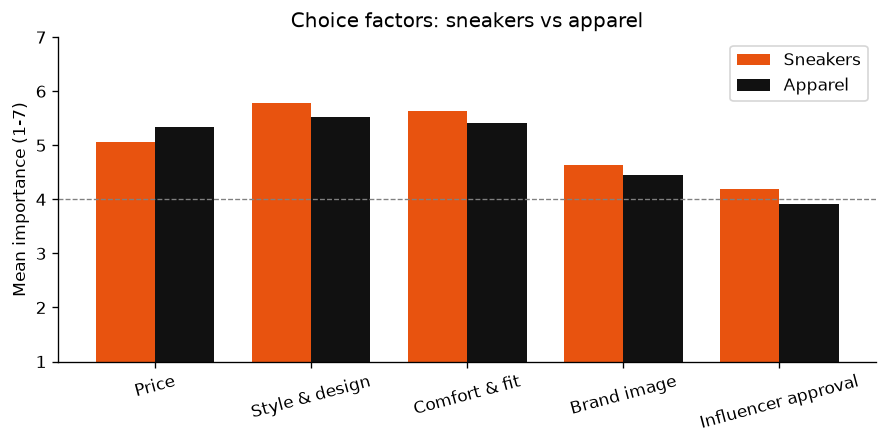

In [50]:
res = []
for name in FACTORS:
    d = clean[["sneaker_" + name, "apparel_" + name]].dropna()
    s, a = d["sneaker_" + name], d["apparel_" + name]
    diff = s - a
    t, p = stats.ttest_rel(s, a)
    ci = stats.t.interval(0.95, len(d) - 1, diff.mean(), stats.sem(diff))
    try: w = stats.wilcoxon(s, a).pvalue
    except ValueError: w = np.nan
    res.append([name, len(d), s.mean(), a.mean(), diff.mean(), f"[{ci[0]:.2f}, {ci[1]:.2f}]", t, p, w, diff.mean() / diff.std(ddof=1)])
rq2 = pd.DataFrame(res, columns=["Factor", "n", "Sneaker mean", "Apparel mean", "Diff (S-A)", "95% CI diff", "t", "p", "Wilcoxon p", "Cohen dz"])

# Holm-Bonferroni adjustment
order = rq2["p"].argsort().values
m = len(rq2); adj = np.empty(m); run = 0
for rank, idx in enumerate(order):
    run = max(run, (m - rank) * rq2["p"].iloc[idx]); adj[idx] = min(1, run)
rq2["p (Holm)"] = adj
rq2["Rank sneakers"] = rq2["Sneaker mean"].rank(ascending=False).astype(int)
rq2["Rank apparel"] = rq2["Apparel mean"].rank(ascending=False).astype(int)
print(rq2.round(3).to_string(index=False))

x = np.arange(len(FACTORS)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(x - w/2, rq2["Sneaker mean"], w, label="Sneakers", color="#e8530f")
ax.bar(x + w/2, rq2["Apparel mean"], w, label="Apparel", color="#111")
ax.axhline(4, ls="--", c="grey", lw=0.8); ax.set_xticks(x, FACTORS, rotation=15)
ax.set_ylim(1, 7); ax.set_ylabel("Mean importance (1-7)"); ax.legend(); ax.set_title("Choice factors: sneakers vs apparel")
plt.tight_layout(); plt.savefig("figs/fig3_factors.png"); plt.show()

## F. RQ3: Apparel attitude and sneaker purchase intention
**H0**: no linear association between attitude toward adidas apparel and intention to buy adidas sneakers (rho = 0). **H1**: rho differs from 0 (we expect positive).
Pearson correlation (Spearman as robustness check) and a simple regression for R-squared. 'Cannot judge' is treated as missing; the last block shows what happens if it is wrongly coded as 0.

n = 32
Pearson r = 0.550, p = 0.0011, 95% CI [0.249, 0.754]
Spearman rho = 0.493, p = 0.0041
Regression: intent = 0.731 + 0.0516 x attitude ; R-squared = 0.302 ; slope p = 0.0011
Each +10 attitude points is associated with +0.52 points of intention (1-7).
Critical |r| for p<.05 at n=32: 0.349

Sensitivity (Cannot judge coded 0, n=35): r = 0.488, p = 0.0029; mean intent = 3.77 vs 4.12 when treated as missing


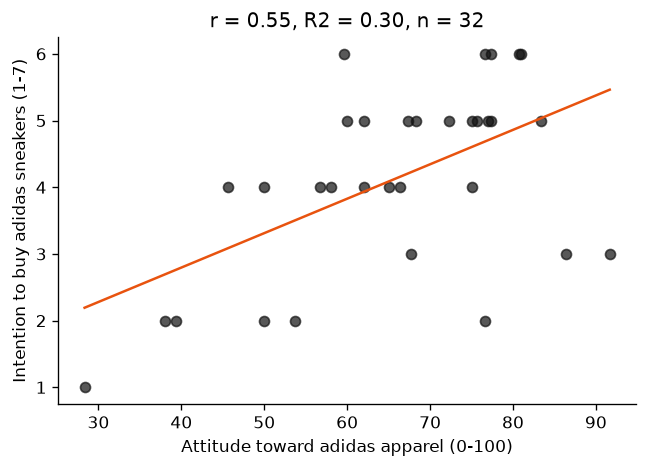

In [51]:
d = clean[["attitude_index", "intent"]].dropna()
r, p = stats.pearsonr(d["attitude_index"], d["intent"])
ci = stats.pearsonr(d["attitude_index"], d["intent"]).confidence_interval()
rho, p_s = stats.spearmanr(d["attitude_index"], d["intent"])
lr = stats.linregress(d["attitude_index"], d["intent"])
print(f"n = {len(d)}")
print(f"Pearson r = {r:.3f}, p = {p:.4f}, 95% CI [{ci.low:.3f}, {ci.high:.3f}]")
print(f"Spearman rho = {rho:.3f}, p = {p_s:.4f}")
print(f"Regression: intent = {lr.intercept:.3f} + {lr.slope:.4f} x attitude ; R-squared = {lr.rvalue**2:.3f} ; slope p = {lr.pvalue:.4f}")
print(f"Each +10 attitude points is associated with {lr.slope*10:+.2f} points of intention (1-7).")
print(f"Critical |r| for p<.05 at n={len(d)}: {stats.t.ppf(.975, len(d)-2)/np.sqrt(len(d)-2+stats.t.ppf(.975, len(d)-2)**2):.3f}")

# Sensitivity: 'Cannot judge' coded 0 (what the slides did)
d0 = clean[["attitude_index", "intent_raw"]].dropna()
r0, p0 = stats.pearsonr(d0["attitude_index"], d0["intent_raw"])
print(f"\nSensitivity (Cannot judge coded 0, n={len(d0)}): r = {r0:.3f}, p = {p0:.4f}; mean intent = {d0['intent_raw'].mean():.2f} vs {d['intent'].mean():.2f} when treated as missing")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(d["attitude_index"], d["intent"], color="#111", alpha=0.7)
xs = np.linspace(d["attitude_index"].min(), d["attitude_index"].max(), 50)
ax.plot(xs, lr.intercept + lr.slope * xs, color="#e8530f")
ax.set_xlabel("Attitude toward adidas apparel (0-100)"); ax.set_ylabel("Intention to buy adidas sneakers (1-7)")
ax.set_title(f"r = {r:.2f}, R2 = {lr.rvalue**2:.2f}, n = {len(d)}")
plt.tight_layout(); plt.savefig("figs/fig4_attitude_intent.png"); plt.show()

## G. RQ4: Purchase intention by ownership group
**H0**: mean intention is equal across the ownership groups. **H1**: at least one group mean differs.
One-way ANOVA with Levene's test for equal variances, eta-squared, Tukey HSD post-hoc test, and Kruskal-Wallis as a robustness check. The three mutually exclusive groups are *Footwear owner*, *Apparel only* and *Neither*; the four-group split is shown descriptively.

                count  mean   std
group3                           
Apparel only        4  3.75  1.71
Footwear owner     25   4.4  1.22
Neither             4   2.0  1.41 

Four-group split (descriptive):
                     count  mean   std
group4                               
Apparel + footwear     18   4.5  1.04
Apparel only            4  3.75  1.71
Footwear only           7  4.14  1.68
Neither                 4   2.0  1.41 

Levene W = 0.192, p = 0.8259
ANOVA F(2, 30) = 5.976, p = 0.0065, eta-squared = 0.285
Kruskal-Wallis H = 7.337, p = 0.0255

Tukey HSD p-values (rows/cols in order): ['Apparel only', 'Footwear owner', 'Neither']
                Apparel only  Footwear owner  Neither
Apparel only           1.000           0.627    0.155
Footwear owner         0.627           1.000    0.005
Neither                0.155           0.005    1.000


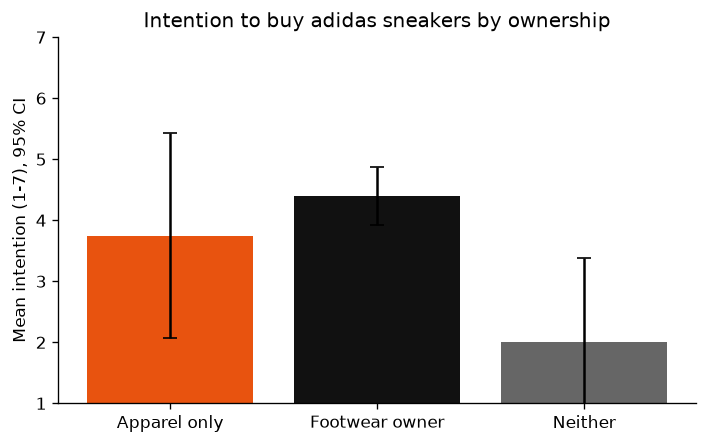

In [52]:
d = clean[["group3", "intent"]].dropna()
g = d.groupby("group3")["intent"].agg(["count", "mean", "std"]).round(2)
print(g, "\n")
print("Four-group split (descriptive):\n", clean.dropna(subset=["intent"]).groupby("group4")["intent"].agg(["count", "mean", "std"]).round(2), "\n")

samples = [x["intent"].values for _, x in d.groupby("group3") if len(x) >= 2]
names = [k for k, x in d.groupby("group3") if len(x) >= 2]
if len(samples) >= 2:
    lev = stats.levene(*samples)
    F, p = stats.f_oneway(*samples)
    grand = d["intent"].mean()
    ss_b = sum(len(s) * (s.mean() - grand) ** 2 for s in samples)
    ss_t = ((d["intent"] - grand) ** 2).sum()
    print(f"Levene W = {lev.statistic:.3f}, p = {lev.pvalue:.4f}")
    print(f"ANOVA F({len(samples)-1}, {len(d)-len(samples)}) = {F:.3f}, p = {p:.4f}, eta-squared = {ss_b/ss_t:.3f}")
    kw = stats.kruskal(*samples); print(f"Kruskal-Wallis H = {kw.statistic:.3f}, p = {kw.pvalue:.4f}")
    th = stats.tukey_hsd(*samples)
    print("\nTukey HSD p-values (rows/cols in order):", names)
    print(pd.DataFrame(th.pvalue, index=names, columns=names).round(3))
else:
    print("Fewer than two groups have n >= 2: merge groups before running ANOVA.")

fig, ax = plt.subplots(figsize=(6, 3.8))
means = d.groupby("group3")["intent"].mean(); sems = d.groupby("group3")["intent"].sem()
ax.bar(means.index, means.values, yerr=1.96 * sems.fillna(0).values, capsize=4, color=["#e8530f", "#111", "#666"][:len(means)])
ax.set_ylim(1, 7); ax.set_ylabel("Mean intention (1-7), 95% CI"); ax.set_title("Intention to buy adidas sneakers by ownership")
plt.tight_layout(); plt.savefig("figs/fig5_intent_groups.png"); plt.show()

## H. Notes for the report
* The effective sample is small (n of about 39), so non-significant results mean *no detectable* effect, not *no effect*; report confidence intervals and effect sizes.
* Respondents are a convenience sample (mostly men, heavy social-media users): results do not generalise to all 18-26 year olds.
* Intention is self-reported and is not the same as purchases.
* Q15 'Cannot judge' is treated as missing; attitude items were collected as 0-100 sliders rather than the 7-point scale first planned.